# 12 — Correzione temporale delle traiettorie (E3)

Ricostruzione del Notebook 03. **Non addestra modelli e non riesegue detection o SAM2**: lavora sui CSV e sulle omografie prodotti dal notebook 09.

**Problema.** Il punto del giocatore è `foot_x = (x1+x2)/2`, `foot_y = y2`, cioè il centro del bordo inferiore della box della maschera (non è una stima anatomica dei piedi). Se la maschera perde le gambe, la box si accorcia e la proiezione sul campo salta.

| Metodo | Descrizione |
|---|---|
| `raw` | baseline: posizioni grezze sul campo riproiettate in pixel |
| `height` | **correttore originale** (`height_corrector.py`): isteresi 0.82/0.90, storico 15, minimo 5; ricostruzione in metri (interpolated / held_last / backfilled / fallback_raw) e riproiezione con la H del frame |
| `pixinterp` | riferimento: sola interpolazione dei pixel mancanti (`thesis_tools.correct`), **senza** filtro di altezza |

Le funzioni di correzione, matching e metriche sono **copiate così come sono** da `scripts/height_corrector.py`, `scripts/court_evaluation.py` e `scripts/thesis_tools.py`.
Protocollo: parametri scelti sulla validation (copertura media per clip, poi RMSE), risultato riportato sul test.
Non serve la GPU: gira anche in locale.

In [1]:
# ==== SETUP COMUNE (uguale in tutti i notebook) ====
import sys, os
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/NBA_Tracking_Project')   # progetto su Drive
    FAST = Path('/content/fast')                                 # disco locale Colab (veloce)
else:
    ROOT = Path(r'F:\Tesi Basket')                               # progetto in locale
    FAST = ROOT / '_cache'
FAST.mkdir(parents=True, exist_ok=True)
assert ROOT.is_dir(), f'Cartella del progetto non trovata: {ROOT}'
print('Progetto:', ROOT)

import json, hashlib
from datetime import datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

VARIANT = 'f0'      # 'f0' = SAM2 baseline, 'redet' = SAM2 + ri-detection (notebook 09)
MANIFEST = ROOT / 'annotations' / f'manifest_sam2_{VARIANT}.csv'
ANNOT = ROOT / 'annotations' / 'annotations.csv'
TASKS = ROOT / 'annotations' / 'tasks.csv'
GATE_PX = 80.0
MAX_GAPS_MAIN = [0, 1, 2, 3, 4, 5, 6]
MAX_GAPS_PIX = [0, 2, 5, 10]

RUN = ROOT / 'experiments' / 'E3_correzione' / (f'run_{VARIANT}_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
RUN.mkdir(parents=True, exist_ok=False); FIG = RUN / 'figure'; FIG.mkdir()
print('Output di questa esecuzione:', RUN)

Progetto: F:\Tesi Basket
Output di questa esecuzione: F:\Tesi Basket\experiments\E3_correzione\run_f0_20261022_142049


## 1. Funzioni originali (copiate dagli script, non modificate)

In [2]:
def flag_height(tracks, ratio_min=.82,recovery_ratio=.90,history_size=15,min_history=5):
    required={'frame','track_id','y1','y2'}
    if not required<=set(tracks): raise ValueError(f'Mancano colonne: {required-set(tracks)}')
    if not 0<ratio_min<=recovery_ratio or not 1<=min_history<=history_size:
        raise ValueError('Parametri altezza non validi')
    q=tracks.sort_values(['track_id','frame']).copy().reset_index(drop=True)
    if q.duplicated(['frame','track_id']).any(): raise ValueError('Frame/ID duplicati')
    q['box_height_px']=pd.to_numeric(q.y2,errors='coerce')-pd.to_numeric(q.y1,errors='coerce')
    q['height_expected_px']=np.nan;q['height_ratio']=np.nan;q['height_suspected']=False
    for _,indices in q.groupby('track_id',sort=False).groups.items():
        history=[]; occluded=False
        for i in indices:
            h=q.at[i,'box_height_px']
            if not np.isfinite(h) or h<=0:
                q.at[i,'height_suspected']=True;occluded=True;continue
            expected=float(np.median(history[-history_size:])) if len(history)>=min_history else np.nan
            ratio=h/expected if np.isfinite(expected) and expected>0 else np.nan
            q.at[i,'height_expected_px']=expected;q.at[i,'height_ratio']=ratio
            suspect=np.isfinite(ratio) and ((not occluded and ratio<ratio_min) or (occluded and ratio<recovery_ratio))
            q.at[i,'height_suspected']=bool(suspect)
            if suspect: occluded=True
            else: occluded=False;history.append(float(h))
    return q


def fill_variant(quality,max_gap,xy_columns=('x_m','y_m'),output_columns=('x_dynamic_m','y_dynamic_m')):
    if not isinstance(max_gap,int) or max_gap<0: raise ValueError('MAX_GAP intero >= 0 richiesto')
    required={'frame','track_id','height_suspected',*xy_columns}
    if not required<=set(quality): raise ValueError(f'Mancano colonne: {required-set(quality)}')
    parts=[]
    for tid,src in quality.groupby('track_id',sort=False):
        g=src.sort_values('frame').set_index('frame')
        frames=np.arange(int(g.index.min()),int(g.index.max())+1)
        g=g.reindex(frames)
        raw=g[list(xy_columns)].to_numpy(dtype=float)
        suspected=g.height_suspected.fillna(True).astype(bool).to_numpy()
        valid=np.isfinite(raw).all(axis=1)&~suspected
        result=raw.copy();result[~valid]=np.nan
        source=np.where(valid,'observed','missing').astype(object)
        i=0
        while i<len(result):
            if valid[i]: i+=1;continue
            start=i
            while i<len(result) and not valid[i]: i+=1
            end=i
            left=start>0 and np.isfinite(result[start-1]).all()
            right=end<len(result) and np.isfinite(result[end]).all()
            if end-start<=max_gap and left and right:
                result[start:end]=np.linspace(result[start-1],result[end],end-start+2)[1:-1]
                source[start:end]='interpolated'
            elif left:
                result[start:end]=result[start-1];source[start:end]='held_last'
            elif right:
                result[start:end]=result[end];source[start:end]='backfilled'
        fallback=~np.isfinite(result).all(axis=1)&np.isfinite(raw).all(axis=1)
        result[fallback]=raw[fallback];source[fallback]='fallback_raw'
        part=pd.DataFrame(dict(frame=frames,track_id=tid,height_suspected=suspected,max_gap=max_gap,source=source))
        part[output_columns[0]]=result[:,0];part[output_columns[1]]=result[:,1]
        parts.append(part)
    return pd.concat(parts,ignore_index=True) if parts else pd.DataFrame(columns=['frame','track_id',*output_columns,'source'])


def to_pixel(positions,homographies,x_col='x_m',y_col='y_m'):
    d=positions.copy();d['foot_x']=np.nan;d['foot_y']=np.nan
    for frame,indices in d.groupby('frame').groups.items():
        h=homographies.get(str(int(frame)))
        if h is None:continue
        h=np.asarray(h,dtype=float)
        if h.shape!=(3,3) or not np.isfinite(h).all():raise ValueError('H immagine->campo feet non valida')
        try:inverse=np.linalg.inv(h)
        except np.linalg.LinAlgError:continue
        xy=d.loc[indices,[x_col,y_col]].to_numpy(dtype=float)/.3048
        q=np.column_stack([xy,np.ones(len(xy))])@inverse.T
        good=np.isfinite(q).all(axis=1)&(np.abs(q[:,2])>1e-10)
        projected=np.full((len(xy),2),np.nan)
        projected[good]=q[good,:2]/q[good,2,None]
        d.loc[indices,['foot_x','foot_y']]=projected
    return d


def load_tracks(path):
    d = pd.read_csv(path)
    required = {'frame', 'track_id', 'foot_x', 'foot_y'}
    if not required <= set(d):
        raise ValueError(f'{path}: colonne richieste {sorted(required)}')
    if d.duplicated(['frame', 'track_id']).any():
        raise ValueError(f'{path}: frame/ID duplicati')
    if d.frame.isna().any() or (d.frame < 0).any() or (d.frame % 1 != 0).any() or d.track_id.isna().any():
        raise ValueError('Frame non interi/negativi o ID mancanti')
    d['track_id'] = d.track_id.astype(str)
    d[['foot_x', 'foot_y']] = d[['foot_x', 'foot_y']].apply(pd.to_numeric, errors='raise')
    if 'mask_area_px' in d:
        d.loc[d.mask_area_px.eq(0), ['foot_x', 'foot_y']] = np.nan
    d[['foot_x', 'foot_y']] = d[['foot_x', 'foot_y']].replace([np.inf, -np.inf], np.nan)
    return d.sort_values(['track_id', 'frame']).reset_index(drop=True)


def correct(d, max_gap):
    """Nuovo baseline di interpolazione; non sostituisce un correttore non fornito.

    Interpola solo buchi interni con entrambi gli estremi finiti dello stesso ID.
    MAX_GAP conta i frame mancanti; non cambia i punti osservati o gli ID.
    """
    if not isinstance(max_gap, int) or max_gap < 0:
        raise ValueError('MAX_GAP deve essere intero >= 0')
    parts = []
    for tid, g in d.groupby('track_id'):
        g = g.set_index('frame').reindex(range(int(g.frame.min()), int(g.frame.max()) + 1))
        g['track_id'] = tid
        g['interpolated'] = False
        valid = np.flatnonzero(np.isfinite(g[['foot_x', 'foot_y']]).all(axis=1))
        for a, b in zip(valid[:-1], valid[1:]):
            if 0 < b - a - 1 <= max_gap:
                for c in ['foot_x', 'foot_y']:
                    g.iloc[a:b+1, g.columns.get_loc(c)] = np.linspace(g.iloc[a][c], g.iloc[b][c], b-a+1)
                g.iloc[a+1:b, g.columns.get_loc('interpolated')] = True
        parts.append(g.rename_axis('frame').reset_index())
    return pd.concat(parts, ignore_index=True) if parts else d.assign(interpolated=False)


def match_annotations(gt, pred, gate):
    """Associazione spaziale 1:1 per frame, indipendente dagli ID predetti."""
    rows = []
    for frame, g in gt.groupby('frame'):
        p = pred[pred.frame.eq(frame)].dropna(subset=['foot_x', 'foot_y'])
        g = g.reset_index(drop=True)
        p = p.reset_index(drop=True)
        matched = {}
        if len(g) and len(p):
            dist = np.linalg.norm(g[['x_px', 'y_px']].to_numpy()[:, None] - p[['foot_x', 'foot_y']].to_numpy()[None], axis=2)
            # Penalità grande: massimizza prima il numero di associazioni entro gate.
            cost = np.where(dist <= gate, dist, (len(g)+len(p)+1)*(gate+1))
            aa, bb = linear_sum_assignment(cost)
            matched = {int(a): (str(p.iloc[b].track_id), float(dist[a,b])) for a,b in zip(aa,bb) if dist[a,b] <= gate}
        for i, r in g.iterrows():
            tid, err = matched.get(i, (None, np.nan))
            rows.append({**r.to_dict(), 'pred_id': tid, 'error_px': err})
    return pd.DataFrame(rows)


def metrics(matches):
    err = matches.error_px.dropna()
    switches = fragments = 0
    seq = matches[matches.sequence_id.fillna('').ne('')]
    for _, g in seq.groupby(['sequence_id', 'player_id']):
        previous = None
        had_match = False
        interrupted = False
        last_frame = None
        for r in g.sort_values('frame').itertuples():
            if last_frame is not None and r.frame != last_frame + 1:
                previous, had_match, interrupted = None, False, False
            last_frame = r.frame
            if pd.isna(r.pred_id):
                interrupted = had_match
                continue
            if previous is not None and r.pred_id != previous:
                switches += 1
            if interrupted:
                fragments += 1
            previous, had_match, interrupted = r.pred_id, True, False
    return dict(n_annotatable=len(matches), n_matched=len(err), coverage=len(err)/len(matches) if len(matches) else None,
                mean_error_px=float(err.mean()) if len(err) else None,
                rmse_px=float(np.sqrt(np.mean(err**2))) if len(err) else None,
                id_switches=switches if len(seq) else None, fragmentations=fragments if len(seq) else None)

## 2. Sezione A (facoltativa) — diagnostica sui vecchi output Boston

**Nessuna ground truth**: salti e velocità **non** dimostrano accuratezza (tenere ferma una posizione li riduce artificialmente), quindi `MAX_GAP` **non** si sceglie da qui.

Boston: 30.00 fps, altezze sospette 258/1650


,method,max_gap,v_p95_m_s,v_max_m_s,pct_v_oltre_10_m_s
0,raw,NaN,16.184,129.143,7.584
1,height,1.0,8.375,75.505,3.537
2,height,2.0,8.223,75.505,3.354
3,height,3.0,8.111,75.505,3.293
4,height,4.0,7.981,75.505,3.171
5,height,5.0,7.978,75.505,3.110
6,height,6.0,7.949,75.505,2.988


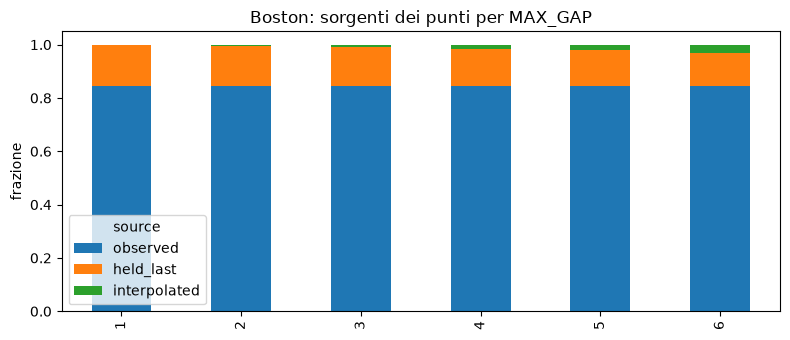

In [3]:
B_TRACKS = ROOT / 'outputs' / 'baseline_v1' / 'boston-celtics-new-york-knicks-game-1-q2-08.09-08.03_tracks.csv'
B_POS = ROOT / 'outputs' / 'baseline_v1' / 'nba_positions_2d.csv'
B_VIDEO = ROOT / 'outputs' / 'baseline_v1' / 'boston-celtics-new-york-knicks-game-1-q2-08.09-08.03_tracking.mp4'

if B_TRACKS.is_file() and B_POS.is_file():
    import cv2
    fps_b = cv2.VideoCapture(str(B_VIDEO)).get(cv2.CAP_PROP_FPS) if B_VIDEO.is_file() else 30.0
    raw_b = load_tracks(B_TRACKS)
    pos_b = pd.read_csv(B_POS, dtype={'track_id': str}); pos_b['x_m'] = pos_b.x_ft * .3048; pos_b['y_m'] = pos_b.y_ft * .3048
    q_b = flag_height(raw_b.merge(pos_b[['frame', 'track_id', 'x_m', 'y_m']], on=['frame', 'track_id'], how='left'))

    def speed_stats(d, x, y):
        d = d.sort_values(['track_id', 'frame']); g = d.groupby('track_id')
        v = (np.hypot(g[x].diff(), g[y].diff()) / (g.frame.diff() / fps_b)).replace([np.inf, -np.inf], np.nan).dropna()
        return {'v_p95_m_s': v.quantile(.95), 'v_max_m_s': v.max(), 'pct_v_oltre_10_m_s': (v > 10).mean() * 100}

    rows, src = [{'method': 'raw', 'max_gap': None, **speed_stats(q_b, 'x_m', 'y_m')}], {}
    for gap in [1, 2, 3, 4, 5, 6]:
        f = fill_variant(q_b, gap)
        rows.append({'method': 'height', 'max_gap': gap, **speed_stats(f, 'x_dynamic_m', 'y_dynamic_m')})
        src[gap] = f.source.value_counts(normalize=True)
    diag_b = pd.DataFrame(rows); diag_b.to_csv(RUN / 'A_boston_diagnostica.csv', index=False)
    print(f'Boston: {fps_b:.2f} fps, altezze sospette {int(q_b.height_suspected.sum())}/{len(q_b)}')
    display(diag_b.round(3))
    pd.DataFrame(src).T.fillna(0).plot.bar(stacked=True, figsize=(8, 3.5), title='Boston: sorgenti dei punti per MAX_GAP')
    plt.ylabel('frazione'); plt.tight_layout(); plt.savefig(FIG / 'A_boston_sorgenti.png', dpi=200); plt.show()
else:
    print('Sezione A saltata: file Boston non trovati.')

## 3. Sezione B — caricamento delle 7 clip e controllo di coerenza

- Le sequenze per le metriche di identità seguono `tasks.csv` (solo i 2 giocatori richiesti per sequenza), come nell'originale.
- Le posizioni grezze riproiettate devono coincidere con `foot_x, foot_y` entro 1 px, altrimenti la clip viene bloccata.

In [4]:
man = pd.read_csv(MANIFEST).fillna('')
gt_all = pd.read_csv(ANNOT, dtype={'player_id': str})
if TASKS.is_file():
    plan = pd.read_csv(TASKS).fillna('')
    if 'required_player_ids' in plan:
        gt_all['sequence_id'] = ''
        for t in plan.itertuples():
            if not t.sequence_id: continue
            ids = [x.strip() for x in str(t.required_player_ids).split(';') if x.strip()]
            sel = gt_all.clip_id.eq(t.clip_id) & gt_all.frame.eq(t.frame) & gt_all.player_id.isin(ids)
            gt_all.loc[sel, 'sequence_id'] = t.sequence_id
assert not gt_all.duplicated(['clip_id', 'frame', 'player_id']).any(), 'Annotazioni duplicate'
gt = gt_all[gt_all.annotatable.eq(1)].copy()
print(f'Annotazioni: {len(gt_all)} etichette, {len(gt)} annotabili, {len(gt_all) - len(gt)} non annotabili (escluse dall\'errore)')

DATA, prov = {}, {'created': datetime.now().isoformat(), 'variant': VARIANT, 'gate_px': GATE_PX,
                  'max_gaps_main': MAX_GAPS_MAIN, 'max_gaps_pix': MAX_GAPS_PIX, 'inputs': {}}
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
for p in [MANIFEST, ANNOT, TASKS]:
    if Path(p).is_file(): prov['inputs'][Path(p).name] = sha(p)

for r in man.itertuples():
    if not (r.tracks_csv and r.positions_csv and r.homographies_json):
        print(f'  {r.clip_id}: SALTATA (percorsi vuoti nel manifest: eseguire il notebook 09)'); continue
    raw = load_tracks(ROOT / r.tracks_csv)
    pos = pd.read_csv(ROOT / r.positions_csv, dtype={'track_id': str})
    assert not pos.duplicated(['frame', 'track_id']).any(), 'Posizioni duplicate'
    pos['x_m'] = pos.x_ft * .3048; pos['y_m'] = pos.y_ft * .3048
    q = flag_height(raw.merge(pos[['frame', 'track_id', 'x_m', 'y_m']], on=['frame', 'track_id'], how='left', validate='one_to_one'))
    H = json.loads((ROOT / r.homographies_json).read_text())
    base = to_pixel(q, H)
    chk = raw.merge(base[['frame', 'track_id', 'foot_x', 'foot_y']], on=['frame', 'track_id'], suffixes=('_raw', '_back'))
    fin = np.isfinite(chk[['foot_x_raw', 'foot_y_raw', 'foot_x_back', 'foot_y_back']]).all(axis=1)
    err = np.hypot(chk.foot_x_raw - chk.foot_x_back, chk.foot_y_raw - chk.foot_y_back)[fin]
    if len(err) == 0 or err.max() > 1.0:
        raise ValueError(f'{r.clip_id}: raw e H non coerenti entro 1 px (max {err.max() if len(err) else "n/d"}): verificare provenienza/verso/unità')
    print(f'  {r.clip_id} [{r.split}]: coerenza OK su {len(err)} punti (max {err.max():.4f} px), altezze sospette {int(q.height_suspected.sum())}/{len(q)}')
    DATA[r.clip_id] = dict(split=r.split, raw=raw, q=q, H=H, base=base)
    prov['inputs'][r.clip_id] = {k: sha(ROOT / getattr(r, k)) for k in ['tracks_csv', 'positions_csv', 'homographies_json']}
    q.to_csv(RUN / f'{r.clip_id}_height_flags.csv', index=False)
(RUN / 'provenance.json').write_text(json.dumps(prov, indent=2))
assert {'validation', 'test'} <= {d['split'] for d in DATA.values()}, 'Servono clip di validation e di test'

Annotazioni: 216 etichette, 176 annotabili, 40 non annotabili (escluse dall'errore)
  clip_01 [validation]: coerenza OK su 963 punti (max 0.0001 px), altezze sospette 134/963
  clip_03 [validation]: coerenza OK su 1310 punti (max 0.0001 px), altezze sospette 344/1410
  clip_04 [test]: coerenza OK su 1257 punti (max 0.0000 px), altezze sospette 235/1330
  clip_05 [test]: coerenza OK su 2735 punti (max 0.0000 px), altezze sospette 890/3060
  clip_06 [test]: coerenza OK su 2153 punti (max 0.0001 px), altezze sospette 947/2718
  clip_07 [validation]: coerenza OK su 1152 punti (max 0.0001 px), altezze sospette 172/1152
  clip_08 [test]: coerenza OK su 695 punti (max 0.0001 px), altezze sospette 288/935


## 4. Predizioni per ogni metodo/parametro e matching con le annotazioni

In [5]:
def predict(clip, method, gap):
    d = DATA[clip]
    if method == 'raw':      return d['base'].assign(source='observed')
    if method == 'height':   return to_pixel(fill_variant(d['q'], gap), d['H'], 'x_dynamic_m', 'y_dynamic_m')
    if method == 'pixinterp':
        p = correct(d['raw'], gap); p['source'] = np.where(p.interpolated, 'interpolated', 'observed'); return p

CANDIDATES = [('raw', 0)] + [('height', g) for g in MAX_GAPS_MAIN] + [('pixinterp', g) for g in MAX_GAPS_PIX]
per_clip, all_m, src_rows = [], [], []
for clip, d in DATA.items():
    a = gt[gt.clip_id.eq(clip)]
    for method, gap in CANDIDATES:
        p = predict(clip, method, gap)
        m = match_annotations(a, p, GATE_PX); m['method'], m['max_gap'], m['split'] = method, gap, d['split']
        all_m.append(m)
        per_clip.append(dict(clip_id=clip, split=d['split'], method=method, max_gap=gap, **metrics(m)))
        src_rows.append(dict(clip_id=clip, method=method, max_gap=gap, **p.source.value_counts().to_dict()))
per_clip = pd.DataFrame(per_clip); matches = pd.concat(all_m, ignore_index=True); sources = pd.DataFrame(src_rows).fillna(0)
per_clip.to_csv(RUN / 'metriche_per_clip_tutti_i_candidati.csv', index=False)
matches.to_csv(RUN / 'matching_gt.csv', index=False); sources.to_csv(RUN / 'sorgenti_punti.csv', index=False)

## 5. Selezione dei parametri sulla validation

In [6]:
val = (per_clip[per_clip.split.eq('validation')].groupby(['method', 'max_gap'])
       .agg(coverage=('coverage', 'mean'), rmse_px=('rmse_px', 'mean'), mean_error_px=('mean_error_px', 'mean')).reset_index())
val.to_csv(RUN / 'validation_selezione.csv', index=False)
selected = {m: int(val[val.method.eq(m)].sort_values(['coverage', 'rmse_px'], ascending=[False, True]).max_gap.iloc[0])
            for m in ['height', 'pixinterp']}
(RUN / 'parametri_selezionati.json').write_text(json.dumps(selected, indent=2))
print('Selezionati sulla validation:', selected); display(val.round(3))

Selezionati sulla validation: {'height': 5, 'pixinterp': 0}


,method,max_gap,coverage,rmse_px,mean_error_px
0,height,0,0.912,24.960,16.334
1,height,1,0.912,24.960,16.334
2,height,2,0.912,24.960,16.334
3,height,3,0.912,24.960,16.334
4,height,4,0.912,24.960,16.334
5,height,5,0.912,24.944,16.296
6,height,6,0.912,24.944,16.296
7,pixinterp,0,0.890,20.596,13.905
8,pixinterp,2,0.890,20.596,13.905
9,pixinterp,5,0.890,20.596,13.905


## 6. Risultati finali sul test (parametri congelati)

In [7]:
FINAL = [('raw', 0), ('height', selected['height']), ('pixinterp', selected['pixinterp'])]
is_final = lambda df: df.apply(lambda r: (r.method, r.max_gap) in FINAL, axis=1)
test_clip = per_clip[per_clip.split.eq('test') & is_final(per_clip)]
test_clip.to_csv(RUN / 'test_per_clip.csv', index=False)
rows = []
for method, gap in FINAL:
    m = matches[matches.split.eq('test') & matches.method.eq(method) & matches.max_gap.eq(gap)].copy()
    m['sequence_id'] = np.where(m.sequence_id.fillna('').ne(''), m.clip_id + ':' + m.sequence_id.fillna(''), '')
    t = test_clip[test_clip.method.eq(method)]
    rows.append(dict(method=method, max_gap=gap, **{f'pooled_{k}': v for k, v in metrics(m).items()},
                     coverage_media_per_clip=t.coverage.mean(), rmse_medio_per_clip=t.rmse_px.mean()))
final = pd.DataFrame(rows).set_index('method'); final.to_csv(RUN / 'test_risultati_finali.csv')
for clip, d in DATA.items():                      # coordinate grezze e corrette con i parametri selezionati
    for method, gap in FINAL: predict(clip, method, gap).to_csv(RUN / f'{clip}_{method}_gap{gap}_coords.csv', index=False)
display(final.round(3))
display(test_clip.pivot_table(index='clip_id', columns='method', values=['coverage', 'rmse_px']).round(3))

,max_gap,pooled_n_annotatable,pooled_n_matched,pooled_coverage,pooled_mean_error_px,pooled_rmse_px,pooled_id_switches,pooled_fragmentations,coverage_media_per_clip,rmse_medio_per_clip
method,,,,,,,,,,
raw,0,91,84,0.923,13.376,17.127,2,0,0.939,17.836
height,5,91,83,0.912,13.148,16.959,2,0,0.921,17.651
pixinterp,0,91,84,0.923,13.376,17.127,2,0,0.939,17.836


coverage                  rmse_px                  
method    height pixinterp    raw  height pixinterp     raw
clip_id                                                    
clip_04    1.000     1.000  1.000  22.163    18.011  18.011
clip_05    0.969     0.969  0.969  10.620    10.620  10.620
clip_06    0.929     1.000  1.000  20.673    25.337  25.337
clip_08    0.786     0.786  0.786  17.147    17.376  17.376

## 7. Grafici

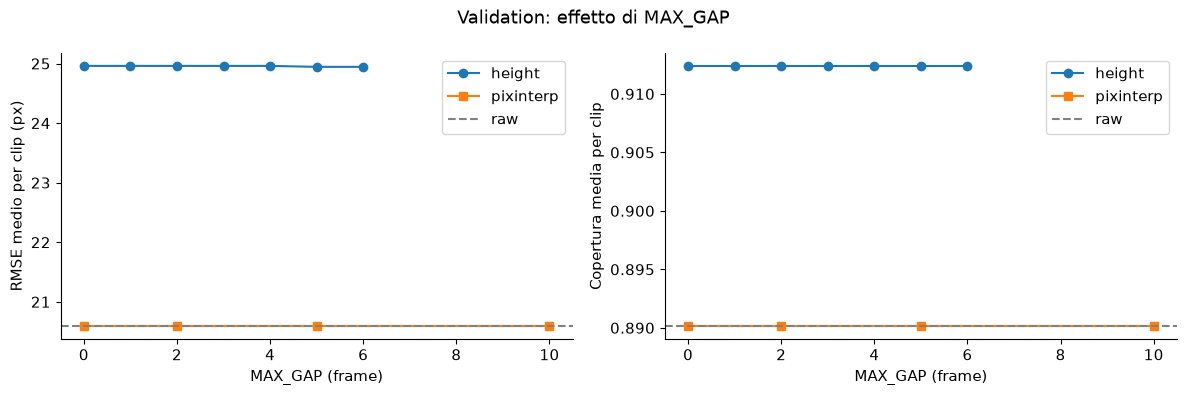

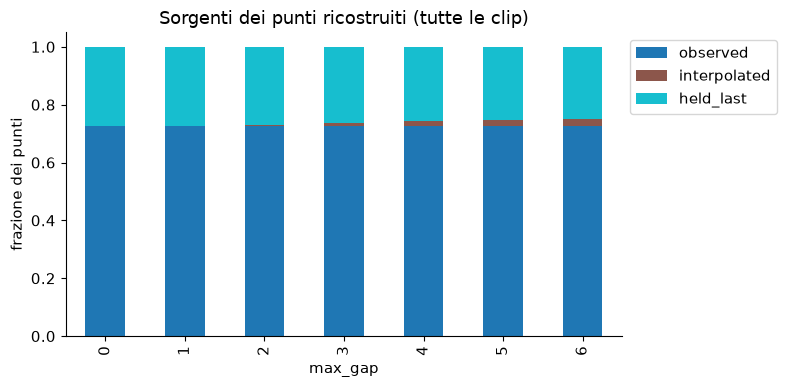

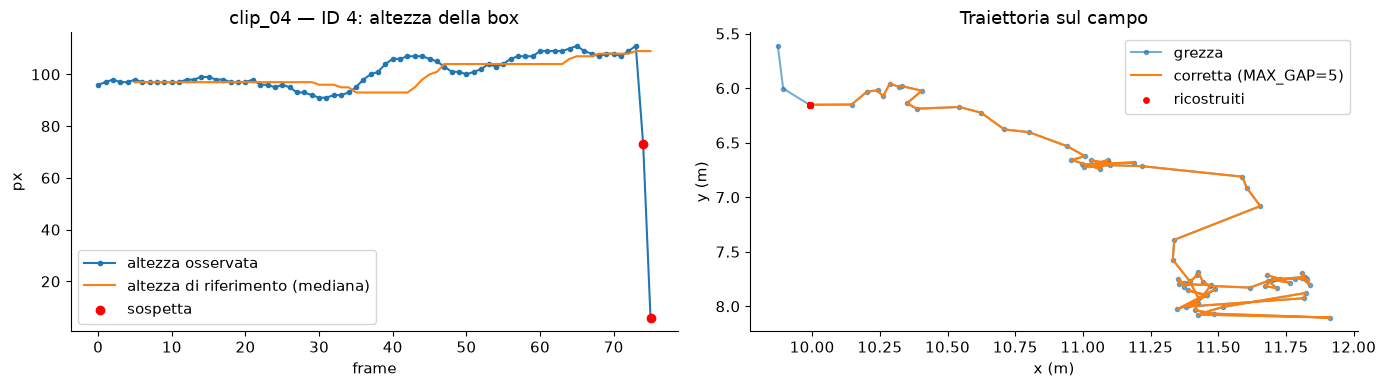

Tutti gli output in F:\Tesi Basket\experiments\E3_correzione\run_f0_20261022_142049


In [8]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(12, 4)); rv = val[val.method.eq('raw')].iloc[0]
for ax, col, lab in zip(axes, ['rmse_px', 'coverage'], ['RMSE medio per clip (px)', 'Copertura media per clip']):
    for method, mk in [('height', 'o'), ('pixinterp', 's')]:
        v = val[val.method.eq(method)]; ax.plot(v.max_gap, v[col], marker=mk, label=method)
    ax.axhline(rv[col], color='gray', ls='--', label='raw'); ax.set_xlabel('MAX_GAP (frame)'); ax.set_ylabel(lab); ax.legend()
fig.suptitle('Validation: effetto di MAX_GAP'); fig.tight_layout(); fig.savefig(FIG / 'validation_vs_maxgap.png', dpi=200); plt.show()

cols = [c for c in ['observed', 'interpolated', 'held_last', 'backfilled', 'fallback_raw', 'missing'] if c in sources]
s = sources[sources.method.eq('height')].groupby('max_gap')[cols].sum()
s.div(s.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(8, 4), colormap='tab10')
plt.ylabel('frazione dei punti'); plt.title('Sorgenti dei punti ricostruiti (tutte le clip)'); plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(FIG / 'sorgenti_ricostruzione.png', dpi=200); plt.show()

clip = next((c for c, d in DATA.items() if d['split'] == 'test'))
q = DATA[clip]['q']; tid = q.groupby('track_id').height_suspected.sum().idxmax()
g = q[q.track_id.eq(tid)].sort_values('frame')
c = fill_variant(q, selected['height']); c = c[c.track_id.eq(tid)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(g.frame, g.box_height_px, '.-', label='altezza osservata')
axes[0].plot(g.frame, g.height_expected_px, '-', label='altezza di riferimento (mediana)')
axes[0].scatter(g.frame[g.height_suspected], g.box_height_px[g.height_suspected], color='red', zorder=3, label='sospetta')
axes[0].set_xlabel('frame'); axes[0].set_ylabel('px'); axes[0].legend(); axes[0].set_title(f'{clip} — ID {tid}: altezza della box')
axes[1].plot(g.x_m, g.y_m, '.-', alpha=.6, label='grezza')
axes[1].plot(c.x_dynamic_m, c.y_dynamic_m, '-', label=f'corretta (MAX_GAP={selected["height"]})')
f = c[c.source.ne('observed')]; axes[1].scatter(f.x_dynamic_m, f.y_dynamic_m, s=15, color='red', zorder=3, label='ricostruiti')
axes[1].set_xlabel('x (m)'); axes[1].set_ylabel('y (m)'); axes[1].invert_yaxis(); axes[1].legend(); axes[1].set_title('Traiettoria sul campo')
fig.tight_layout(); fig.savefig(FIG / 'altezza_e_traiettoria.png', dpi=200); plt.show()
print('Tutti gli output in', RUN)

## 8. Bonus — SAM2 baseline vs SAM2 + ri-detection sulle tue clip

Se esistono entrambi i manifest (`f0` e `redet`), confronta il **tracking grezzo** (nessuna correzione, nessun parametro da scegliere → si possono usare tutte le clip): la ri-detection dovrebbe aumentare la copertura (giocatori mai tracciati, es. portatore di palla della clip_01).

In [9]:
rows = []
for v in ['f0', 'redet']:
    mp = ROOT / 'annotations' / f'manifest_sam2_{v}.csv'
    if not mp.is_file(): continue
    for r in pd.read_csv(mp).fillna('').itertuples():
        if not r.tracks_csv: continue
        m = match_annotations(gt[gt.clip_id.eq(r.clip_id)], load_tracks(ROOT / r.tracks_csv), GATE_PX)
        rows.append(dict(variant=v, clip_id=r.clip_id, split=r.split, **metrics(m)))
if rows:
    cmp_ = pd.DataFrame(rows); cmp_.to_csv(RUN / 'confronto_sam2_f0_vs_redet.csv', index=False)
    display(cmp_.pivot_table(index='clip_id', columns='variant', values=['coverage', 'rmse_px', 'id_switches']).round(3))
    display(cmp_.groupby('variant')[['coverage', 'rmse_px', 'mean_error_px']].mean().round(3))

,coverage,id_switches,rmse_px
variant,f0,f0,f0
clip_id,,,
clip_01,0.904,0.0,30.112
clip_03,0.933,NaN,19.248
clip_04,1.000,NaN,18.011
clip_05,0.969,2.0,10.620
clip_06,1.000,NaN,25.337
clip_07,0.833,NaN,12.429
clip_08,0.786,0.0,17.376


,coverage,rmse_px,mean_error_px
variant,,,
f0,0.918,19.019,13.999


## Limiti da dichiarare
- Il correttore non recupera un giocatore mai tracciato (portatore di palla della clip_01: problema di tracking → sezione 8 / notebook 09 `redet`).
- Non corregge gli scambi di identità né gli errori sistematici dell'omografia; può eliminare variazioni reali (postura, salto) e mantenere una posizione errata nei buchi lunghi (`held_last`).
- Errori in **pixel**, condizionati ai match entro 80 px: riportare sempre la copertura. La verifica di coerenza a 1 px non valida la calibrazione.
- Identità: solo nelle 3 sequenze di 8 frame × 2 giocatori; **non** sono HOTA/MOTA/IDF1.
- 7 clip; categorie di inquadratura/camera non verificate in `scene_intervals.csv` → nessuna analisi per categoria.